# Задание 1. Инициализация, активации и сходимость SGD

Исследуем сеть `784 → 512 → 256 → 256 → 128 → 10` из условия на FashionMNIST.
Обязательные активации: **ReLU, tanh, identity**. Дополнительный пункт: **LeakyReLU(0.1)**.
Для каждой сравним пять инициализаций, распределения выходов и их градиентов во всех слоях,
градиенты весов и обучение с обычным SGD.

Использованы приёмы из `../notebooks/pytorch_intro.ipynb`: `nn.Module`, `ModuleList`,
`DataLoader`, `CrossEntropyLoss`, `zero_grad → backward → step`, отдельная валидация.
Весь код решения и результаты находятся в этом ноутбуке. Выполнение: **Restart Kernel → Run All**.
Данные скачиваются в системный временный каталог (путь можно переопределить через
`FASHION_MNIST_ROOT`); первый запуск требует интернета. Зависимости уже перечислены
в `requirements.txt`. Сохранённый эксперимент выполнен на CPU.


In [1]:
import copy
import math
import os
import platform
import random
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import Markdown, display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

SEEDS = (17, 42, 2026)
SPLIT_SEED = 2026
EPOCHS = 10
BATCH_SIZE = 256
LR = 0.03
DEVICE = torch.device("cpu")  # Один backend для всех сравниваемых конфигураций.
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.2, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 15)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(SEEDS[0])
print({"Python": platform.python_version(), "torch": torch.__version__,
       "torchvision": torchvision.__version__, "numpy": np.__version__,
       "pandas": pd.__version__, "device": str(DEVICE), "seeds": SEEDS})


{'Python': '3.12.13', 'torch': '2.14.1', 'torchvision': '0.29.1', 'numpy': '2.4.6', 'pandas': '3.0.3', 'device': 'cpu', 'seeds': (17, 42, 2026)}


## 1. Что должна сохранять инициализация

Для линейного слоя $z_j=\sum_{i=1}^{n_{in}}W_{ji}h_i$ при независимых,
центрированных весах приблизительно
$$E[z_j^2]\approx n_{in}\operatorname{Var}(W)E[h_i^2].$$
Для обратного прохода при аналогичных предположениях появляется множитель $n_{out}$
и квадрат производной активации. Это приближения: пиксели FashionMNIST коррелированы,
а веса, активации и градиенты не обязаны быть независимыми.

* **Xavier:** $\operatorname{Var}(W)=g^2\,2/(n_{in}+n_{out})$ — компромисс между
  прямым и обратным проходами. Основной вариант использует $g=1$.
* **ReLU:** для симметричного входа $E[\mathrm{ReLU}(z)^2]=E[z^2]/2$.
  He с $\operatorname{Var}(W)=2/n_{in}$ компенсирует этот множитель.
  Сохраняется второй момент, а не обязательно дисперсия: среднее после ReLU положительно.
* **tanh:** при большом $|z|$ производная $1-\tanh^2(z)$ близка к нулю.
  Сравним Xavier с $g=1$ и рекомендованным в PyTorch $g=5/3$.
  Больший gain не гарантирует лучшие результаты для любых данных и глубины.
* **Identity:** нелинейности нет. Xavier ($g=1$) балансирует два направления;
  дополнительно рассмотрим $\operatorname{Var}(W)=1/n_{in}$ (LeCun normal),
  сохраняющую масштаб прямого прохода. Композиция таких слоёв остаётся аффинной моделью,
  хотя оптимизация её произведения матриц отличается от обучения одного слоя.
* **LeakyReLU(0.1):** второй момент умножается на $(1+0.1^2)/2$, поэтому
  He использует дисперсию $2/[(1+0.1^2)n_{in}]$. На отрицательной полуоси производная 0.1.

При неодинаковой ширине слоёв нельзя одной дисперсией весов одновременно точно сохранить
покоординатные вторые моменты в обоих направлениях. Поэтому ищем отсутствие обнуления,
насыщения и роста/падения на многие порядки, а не идеально горизонтальные кривые.

Источники формул: [Glorot и Bengio, 2010](https://proceedings.mlr.press/v9/glorot10a.html),
[He et al., 2015](https://arxiv.org/abs/1502.01852),
[PyTorch: nn.init](https://docs.pytorch.org/docs/2.14/nn.init.html).


In [2]:
ACTIVATIONS = {
    "ReLU": nn.ReLU,
    "tanh": nn.Tanh,
    "identity": nn.Identity,
    "LeakyReLU": lambda: nn.LeakyReLU(negative_slope=0.1),
}
INITIALIZATIONS = ("zeros", "normal_small", "normal_large", "xavier", "matched")
INIT_LABELS = {
    "zeros": "Constant 0",
    "normal_small": "Normal std=0.01",
    "normal_large": "Normal std=1",
    "xavier": "Xavier gain=1",
    "matched": "Activation-specific",
}
MATCHED_LABELS = {"ReLU": "He (ReLU)", "tanh": "Xavier gain=5/3",
                  "identity": "LeCun normal", "LeakyReLU": "He (a=0.1)"}

class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10,
                 hidden_sizes=(512, 256, 256, 128)):
        super().__init__()
        layers = []
        layer_sizes = [input_size] + list(hidden_sizes)
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            # Отдельный экземпляр активации удобен для hooks каждого слоя.
            layers.extend([nn.Linear(n_in, n_out), copy.deepcopy(act_fn)])
        layers.append(nn.Linear(layer_sizes[-1], num_classes))
        self.layers = nn.ModuleList(layers)
        self.config = {"act_fn": act_fn.__class__.__name__, "input_size": input_size,
                       "num_classes": num_classes, "hidden_sizes": list(hidden_sizes)}

    def forward(self, x):
        x = x.reshape(x.size(0), -1)
        for layer in self.layers:
            x = layer(x)
        return x  # Логиты: CrossEntropyLoss сама учитывает log-softmax.

@torch.no_grad()
def initialize(model, method, activation):
    if method not in INITIALIZATIONS:
        raise ValueError(method)
    linear_layers = [layer for layer in model.layers if isinstance(layer, nn.Linear)]
    for i, layer in enumerate(linear_layers):
        nn.init.zeros_(layer.bias)
        if method == "zeros":
            nn.init.zeros_(layer.weight)
        elif method == "normal_small":
            nn.init.normal_(layer.weight, std=0.01)
        elif method == "normal_large":
            nn.init.normal_(layer.weight, std=1.0)
        elif method == "xavier" or i == len(linear_layers) - 1:
            # В matched выходной линейный слой не получает gain нелинейности.
            nn.init.xavier_normal_(layer.weight, gain=1.0)
        elif method == "matched":
            if activation == "ReLU":
                nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu")
            elif activation == "LeakyReLU":
                nn.init.kaiming_normal_(layer.weight, a=0.1, mode="fan_in",
                                        nonlinearity="leaky_relu")
            elif activation == "tanh":
                nn.init.xavier_normal_(layer.weight, gain=nn.init.calculate_gain("tanh"))
            elif activation == "identity":
                nn.init.normal_(layer.weight, std=1 / math.sqrt(layer.in_features))
            else:
                raise ValueError(activation)
        else:
            raise ValueError(method)
    return model

def make_model(activation, initialization, seed):
    if initialization not in INITIALIZATIONS:
        raise ValueError(initialization)
    seed_everything(seed)
    model = BaseNetwork(ACTIVATIONS[activation]())
    return initialize(model, initialization, activation).to(DEVICE)

example_model = make_model("ReLU", "matched", SEEDS[0])
print(example_model)
print("Параметров:", sum(p.numel() for p in example_model.parameters()))


BaseNetwork(
  (layers): ModuleList(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Linear(in_features=128, out_features=10, bias=True)
  )
)
Параметров: 633226


Нулевая константа — намеренно вырожденный контроль: скрытые выходы и градиенты весов
обнуляются; обучаться может только последнее смещение. Ненулевая одинаковая константа
также не нарушает симметрию нейронов, но не обязана давать нулевые градиенты.
Малый/большой случайный масштаб проверяет затухание/взрыв без учёта ширины слоя.
Во всех вариантах смещения равны нулю. В `matched` меняется инициализация скрытых слоёв;
выходной слой, как и в обычном Xavier, имеет gain=1. В остальных контролях выбранная
инициализация применяется ко всем пяти линейным слоям.


## 2. FashionMNIST и протокол сравнения

Официальный train делим стратифицированно на **50 000 train + 10 000 validation**.
Все 10 000 официальных test-изображений используем только после выбора конфигураций
по validation. Нормализацию `(x / 255 − mean) / std` считаем только на train.
Источник данных: [официальный FashionMNIST](https://github.com/zalandoresearch/fashion-mnist).

Для каждого seed модели видят одинаковый порядок батчей; начальные стандартные
нормальные случайные числа в соответствующих слоях также совпадают, отличаясь масштабом.
Разбиение фиксировано для всех seed. Это позволяет сравнить варианты попарно.


In [3]:
DATA_ROOT = Path(os.environ.get("FASHION_MNIST_ROOT",
                               str(Path(tempfile.gettempdir()) / "spbu_task1_data")))
# HTTPS-зеркало авторов; torchvision проверяет контрольные суммы архивов.
class FashionMNIST(datasets.FashionMNIST):
    mirrors = ["https://raw.githubusercontent.com/zalandoresearch/"
               "fashion-mnist/master/data/fashion/"] + datasets.FashionMNIST.mirrors

raw_train = FashionMNIST(root=DATA_ROOT, train=True, download=True)
split_generator = torch.Generator().manual_seed(SPLIT_SEED)
train_parts, val_parts = [], []
for label in range(10):
    indices = (raw_train.targets == label).nonzero(as_tuple=True)[0]
    indices = indices[torch.randperm(len(indices), generator=split_generator)]
    val_parts.append(indices[:1000])
    train_parts.append(indices[1000:])
train_indices, val_indices = torch.cat(train_parts), torch.cat(val_parts)
assert not torch.isin(train_indices, val_indices).any()
assert len(train_indices) + len(val_indices) == len(raw_train)

train_x = raw_train.data[train_indices].float().unsqueeze(1).div_(255)
val_x = raw_train.data[val_indices].float().unsqueeze(1).div_(255)
train_y, val_y = raw_train.targets[train_indices], raw_train.targets[val_indices]
train_mean, train_std = train_x.mean().item(), train_x.std(unbiased=False).item()
train_x.sub_(train_mean).div_(train_std)
val_x.sub_(train_mean).div_(train_std)
train_dataset, val_dataset = TensorDataset(train_x, train_y), TensorDataset(val_x, val_y)
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False, num_workers=0)

# Один сбалансированный батч из train для всех диагностик до обучения.
probe_generator = torch.Generator().manual_seed(123)
probe_indices = torch.cat([
    (train_y == c).nonzero(as_tuple=True)[0][
        torch.randperm(int((train_y == c).sum()), generator=probe_generator)[:32]]
    for c in range(10)
])
probe_x, probe_y = train_x[probe_indices].to(DEVICE), train_y[probe_indices].to(DEVICE)
print(f"train={len(train_dataset)}, validation={len(val_dataset)}, probe={len(probe_y)}")
print(f"Нормализация train: mean={train_mean:.6f}, std={train_std:.6f}")
display(pd.DataFrame({"class": raw_train.classes,
                      "train": torch.bincount(train_y).numpy(),
                      "validation": torch.bincount(val_y).numpy()}))


train=50000, validation=10000, probe=320
Нормализация train: mean=0.285913, std=0.352992


,class,train,validation
0,T-shirt/top,5000,1000
1,Trouser,5000,1000
2,Pullover,5000,1000
3,Dress,5000,1000
4,Coat,5000,1000
5,Sandal,5000,1000
6,Shirt,5000,1000
7,Sneaker,5000,1000
8,Bag,5000,1000
9,Ankle boot,5000,1000


## 3. Активации и градиенты до обучения

Hooks сохраняют выход **каждого** модуля: $L_k$ — выход линейного слоя до нелинейности,
$A_k$ — после неё; $L_5$ — логиты. `retain_grad()` позволяет получить
$\partial\mathcal L/\partial t$ для промежуточного выхода $t$; отдельно измеряем
$\partial\mathcal L/\partial W_k$. Hooks удаляются после диагностики.
Для identity выходы $L_k$ и $A_k$ — один тензор, поэтому их значения и градиенты совпадают.

Потери: средняя cross-entropy на одном и том же батче из 320 изображений.
Таким образом, размер батча не объясняет различия градиентов между экспериментами.
RMS — $\sqrt{\operatorname{mean}(t^2)}$ — сравнивает масштаб одного элемента независимо
от количества параметров. Boxplot показывает медиану, квартили и 1–99-й процентили;
выбросы вне усов скрыты только на рисунке, RMS считается по всем значениям.
Ось `symlog` содержит линейную область у нуля, поэтому точные нули не заменены эпсилоном.


In [4]:
def rms(tensor):
    return tensor.detach().double().square().mean().sqrt().item()

def box_stats(tensor, label):
    values = tensor.detach().float().cpu().reshape(-1)
    q = torch.quantile(values, torch.tensor([0.01, 0.25, 0.5, 0.75, 0.99]))
    return dict(label=label, whislo=q[0].item(), q1=q[1].item(), med=q[2].item(),
                q3=q[3].item(), whishi=q[4].item(), fliers=[])

def diagnose(activation, initialization, seed):
    model = make_model(activation, initialization, seed)
    saved, handles = {}, []
    names = [f"L{i // 2 + 1}" if i % 2 == 0 else f"A{i // 2 + 1}"
             for i in range(len(model.layers))]
    def hook_for(name):
        def hook(module, inputs, output):
            output.retain_grad()
            saved[name] = output
        return hook
    try:
        for name, layer in zip(names, model.layers):
            handles.append(layer.register_forward_hook(hook_for(name)))
        model.zero_grad(set_to_none=True)
        logits = model(probe_x)
        loss = nn.functional.cross_entropy(logits, probe_y)
        loss.backward()
        rows, activation_boxes, gradient_boxes, weight_rows = [], [], [], []
        for position, name in enumerate(names):
            output = saved[name]
            assert output.grad is not None
            assert torch.isfinite(output).all() and torch.isfinite(output.grad).all()
            rows.append({"activation": activation, "init": initialization, "seed": seed,
                         "layer": name, "position": position,
                         "activation_rms": rms(output), "gradient_rms": rms(output.grad),
                         "mean": output.detach().mean().item(),
                         "std": output.detach().std(unbiased=False).item(),
                         "zero_fraction": (output.detach() == 0).float().mean().item(),
                         "tanh_saturation": ((output.detach().abs() > 0.99).float().mean().item()
                                             if activation == "tanh" and name.startswith("A")
                                             else float("nan"))})
            if seed == SEEDS[0]:
                activation_boxes.append(box_stats(output, name))
                gradient_boxes.append(box_stats(output.grad, name))
        for name, layer in zip(names, model.layers):
            if isinstance(layer, nn.Linear):
                weight_rows.append({"activation": activation, "init": initialization,
                                    "seed": seed, "layer": name,
                                    "weight_grad_rms": rms(layer.weight.grad)})
        return rows, weight_rows, (activation_boxes, gradient_boxes), loss.item()
    finally:
        for handle in handles:
            handle.remove()

layer_rows, weight_rows, diagnostic_boxes, initial_losses = [], [], {}, []
for activation in ACTIVATIONS:
    for initialization in INITIALIZATIONS:
        for seed in SEEDS:
            rows, weights, boxes, loss = diagnose(activation, initialization, seed)
            layer_rows.extend(rows)
            weight_rows.extend(weights)
            initial_losses.append({"activation": activation, "init": initialization,
                                   "seed": seed, "initial_ce": loss})
            if seed == SEEDS[0]:
                diagnostic_boxes[activation, initialization] = boxes
layer_stats = pd.DataFrame(layer_rows)
weight_stats = pd.DataFrame(weight_rows)
print(f"Диагностировано {len(ACTIVATIONS) * len(INITIALIZATIONS) * len(SEEDS)} моделей.")
display(pd.DataFrame(initial_losses).groupby(["activation", "init"])
        .initial_ce.agg(["mean", "std"]).round(5))


Диагностировано 60 моделей.


mean          std
activation init                                   
LeakyReLU  matched       2.716850e+00      0.08240
           normal_large  5.035443e+05  40743.42830
           normal_small  2.302590e+00      0.00000
           xavier        2.367340e+00      0.02446
           zeros         2.302590e+00      0.00000
ReLU       matched       2.727120e+00      0.09862
           normal_large  4.996291e+05  52095.93058
           normal_small  2.302590e+00      0.00000
           xavier        2.367310e+00      0.03015
           zeros         2.302590e+00      0.00000
identity   matched       3.000300e+00      0.02654
           normal_large  2.679672e+06  33920.31314
           normal_small  2.302580e+00      0.00000
           xavier        3.661620e+00      0.04084
           zeros         2.302590e+00      0.00000
tanh       matched       2.702390e+00      0.01445
           normal_large  1.715448e+01      0.10701
           normal_small  2.302580e+00      0.00000
           xavier        2.448180e+00      0.00411
           zeros         2.302590e+00      0.00000

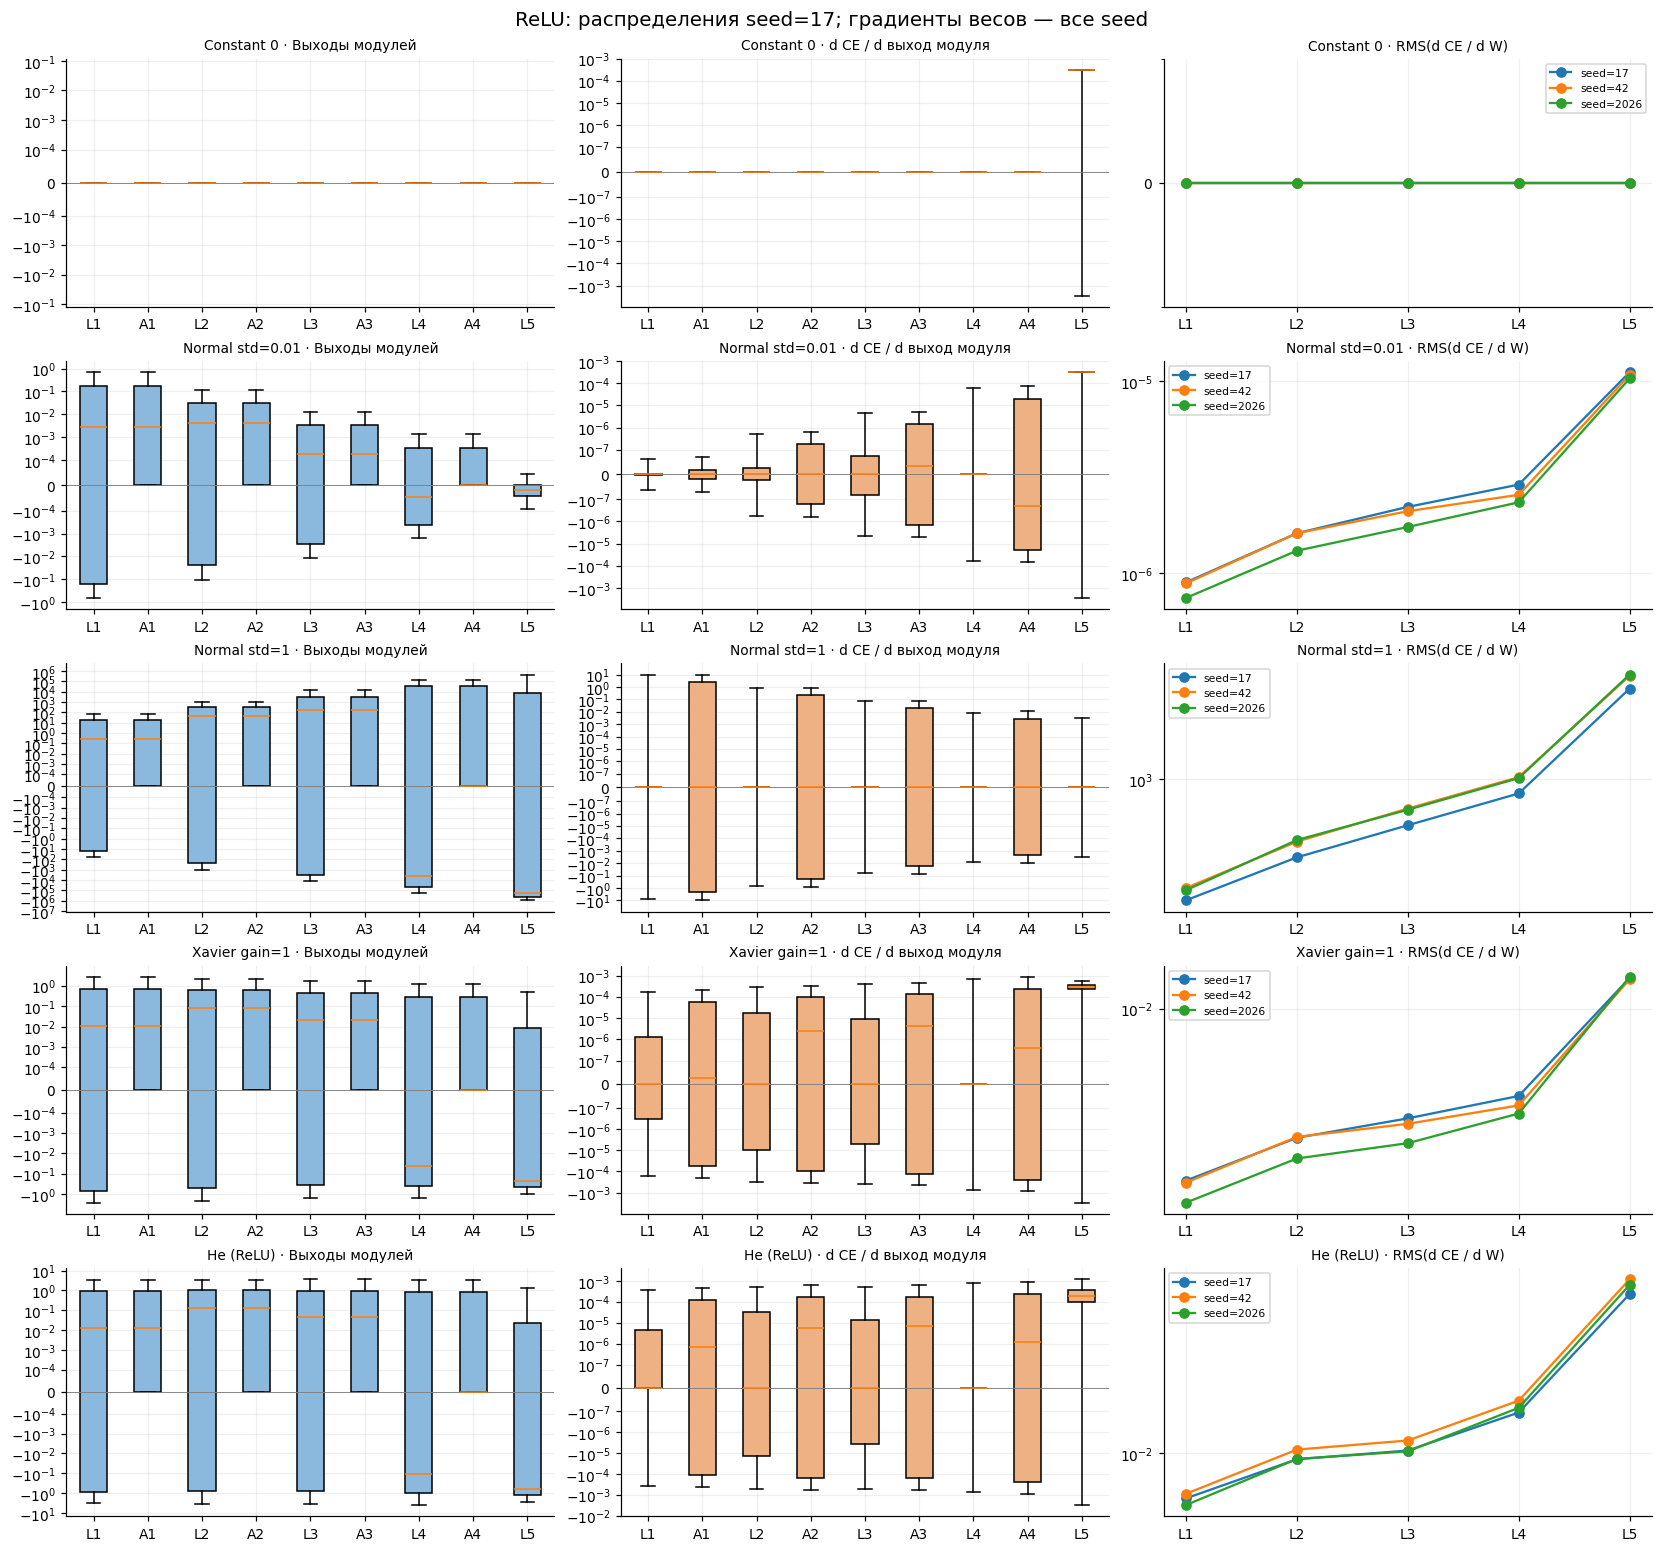

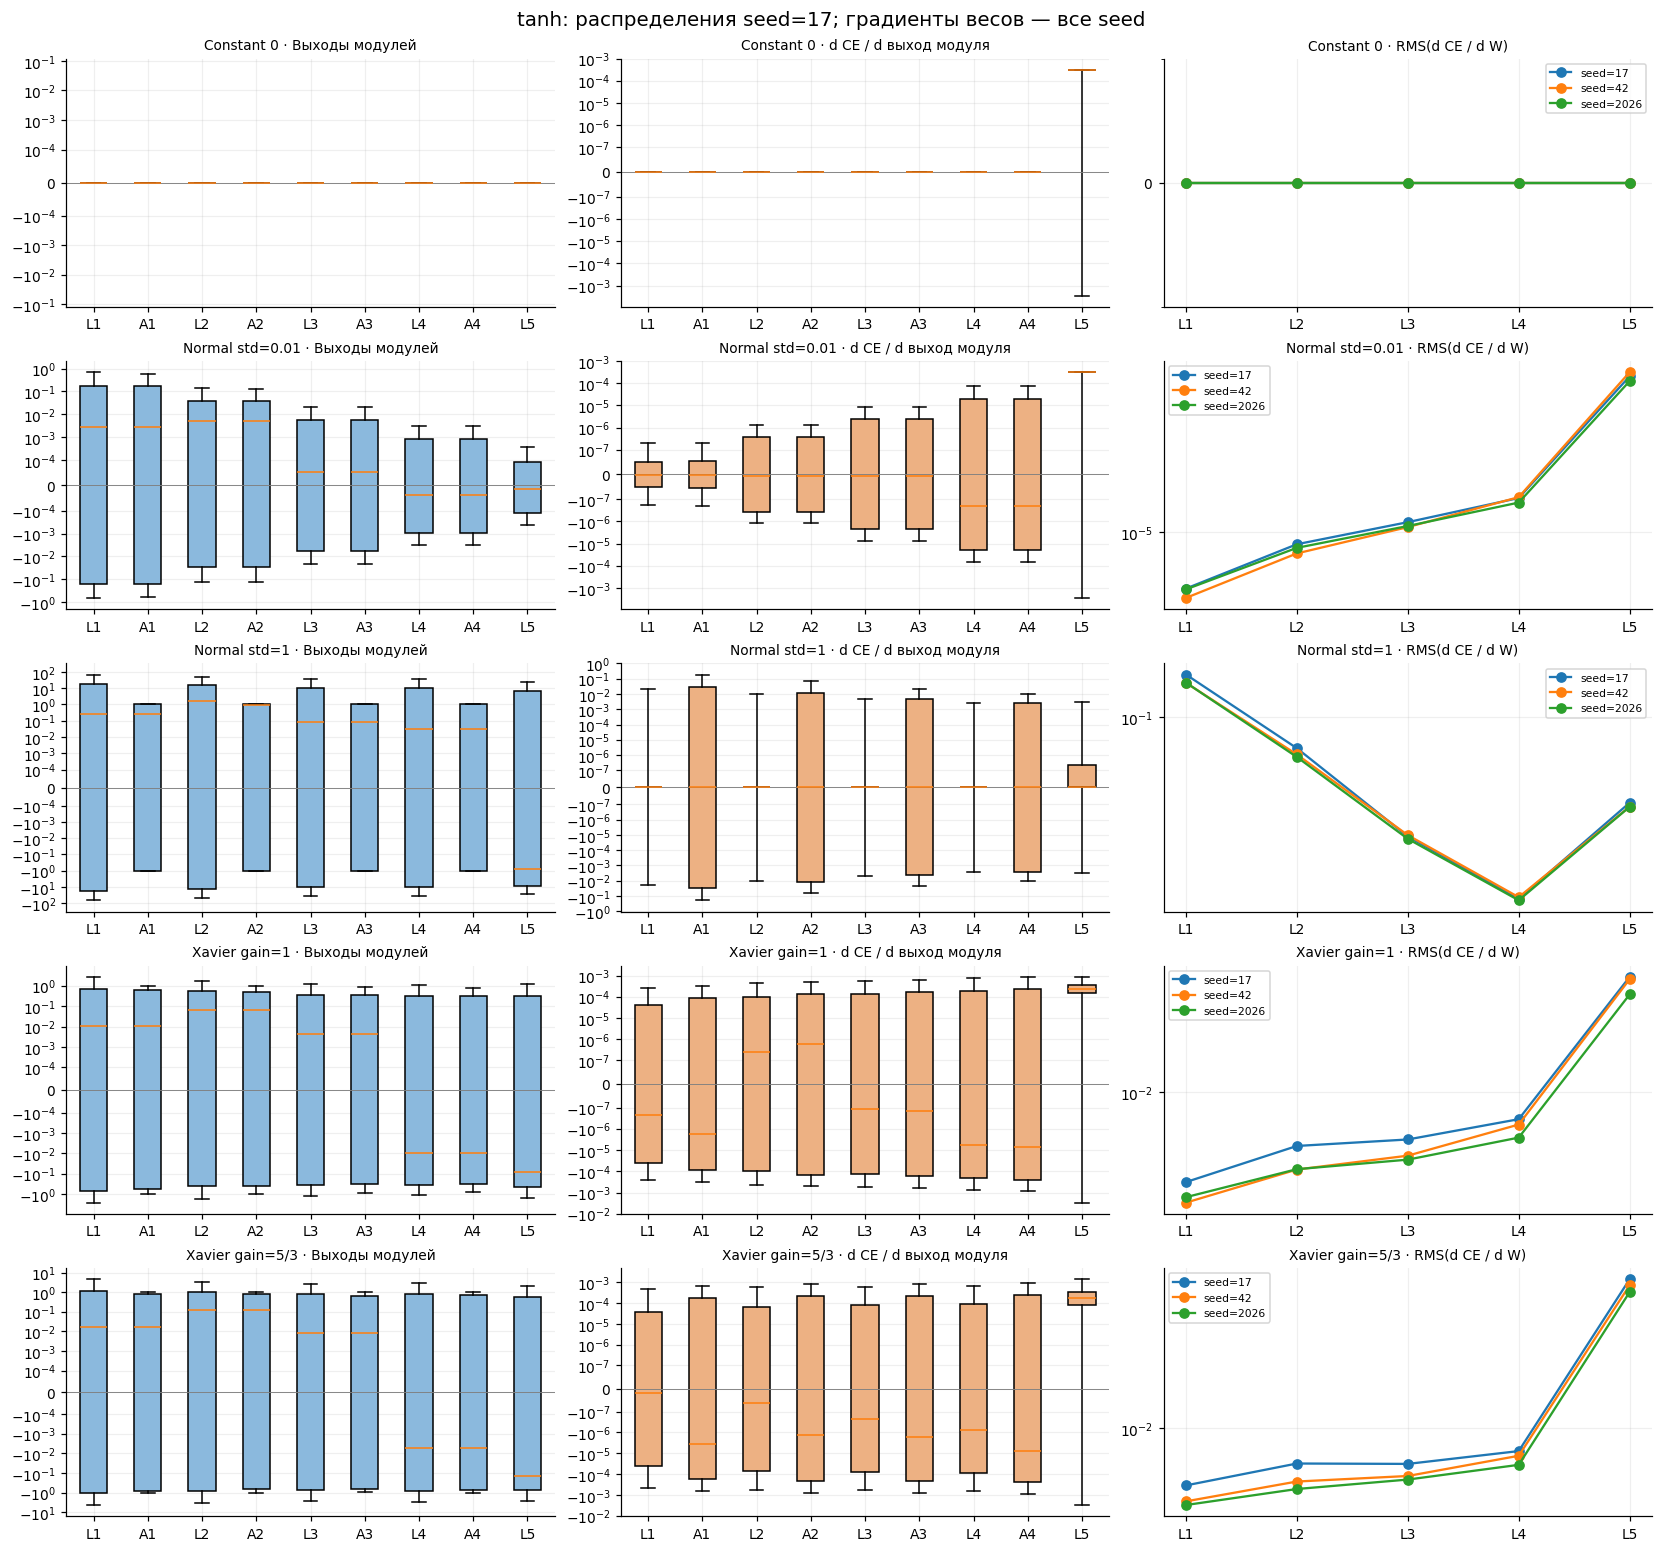

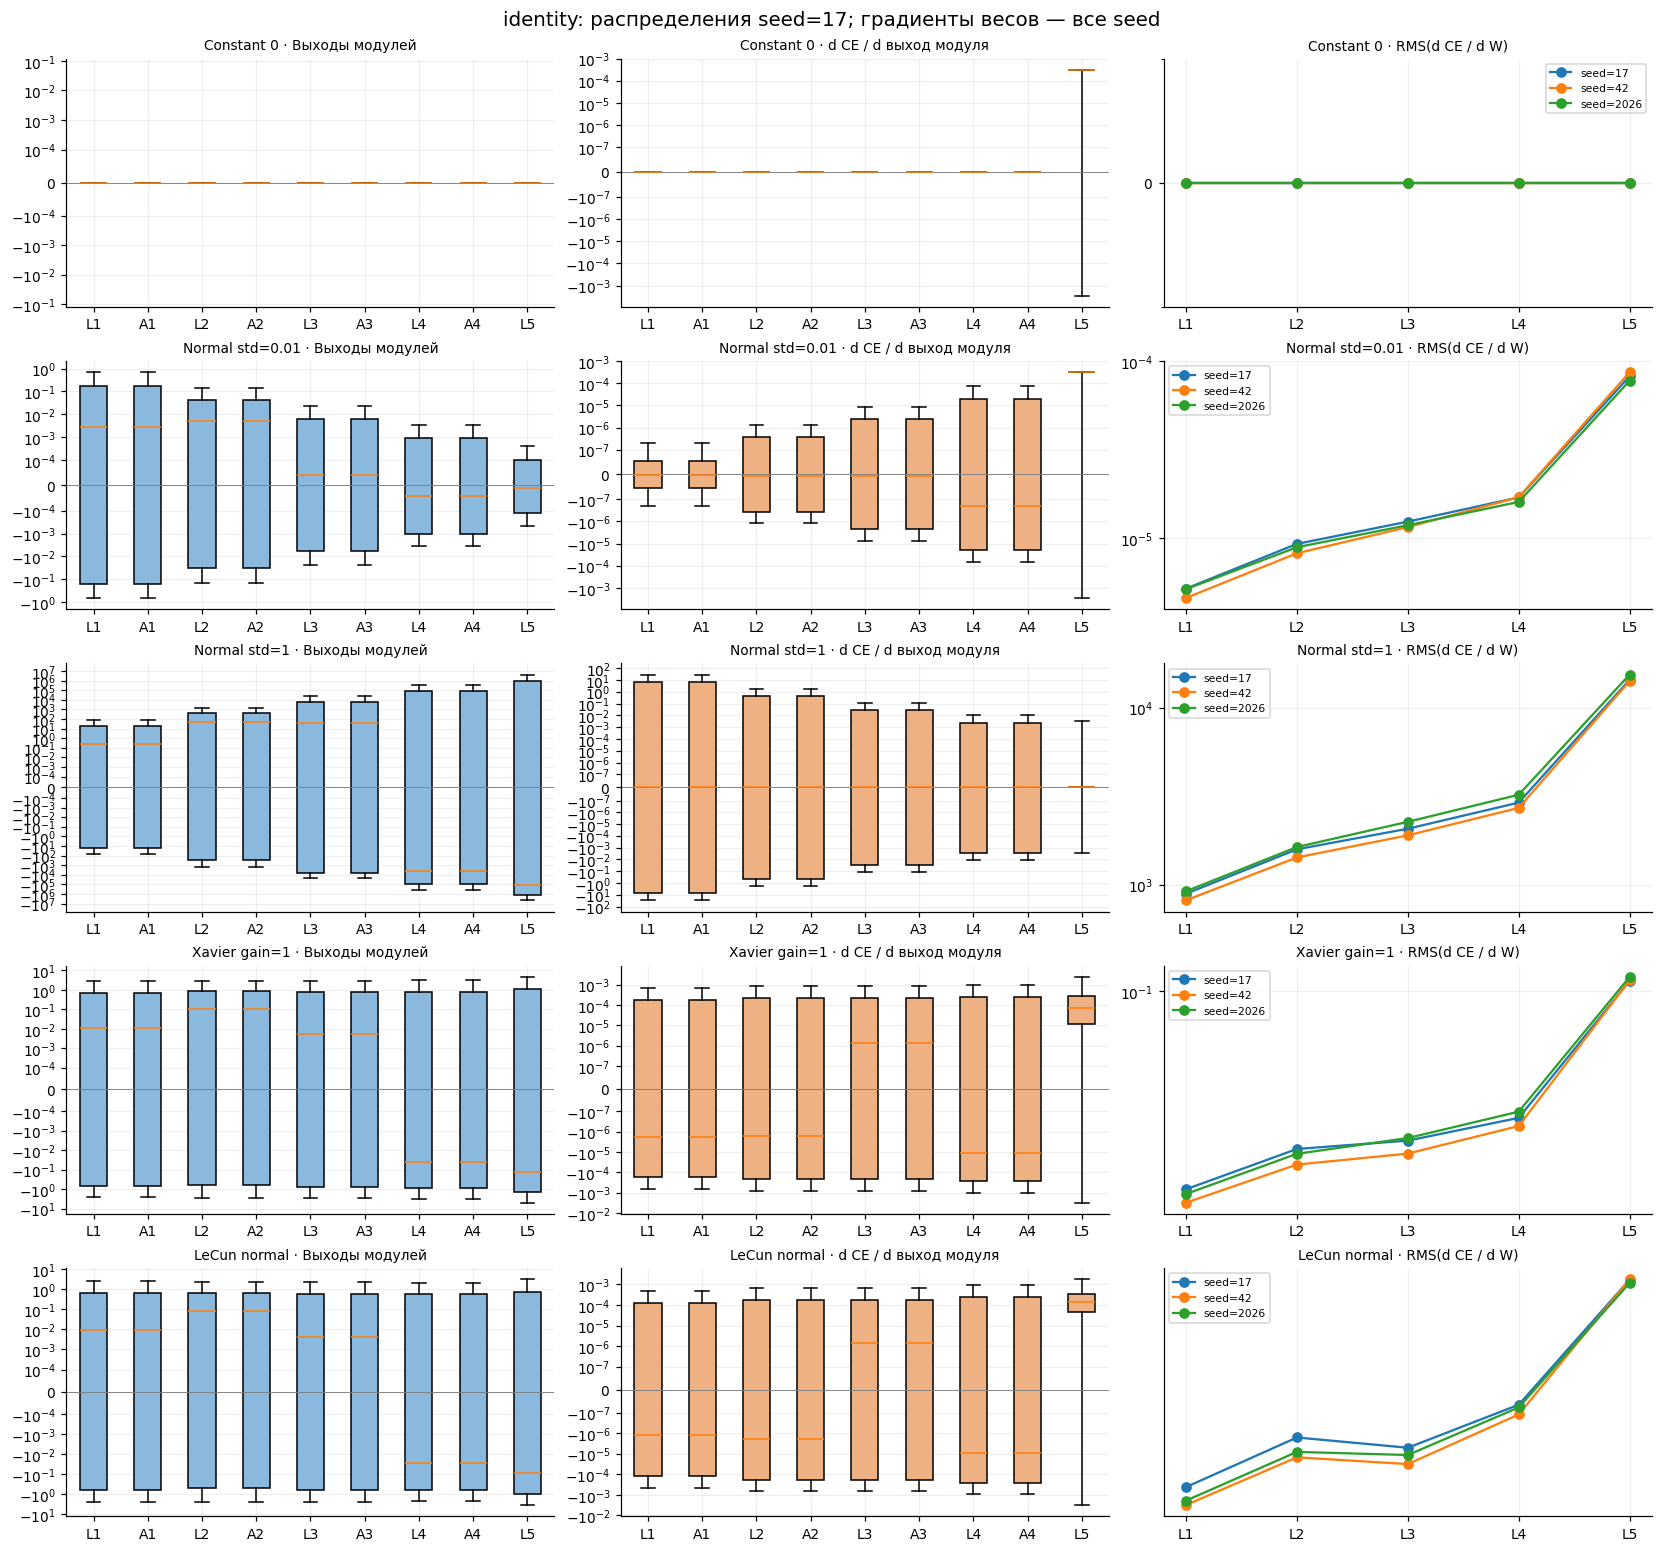

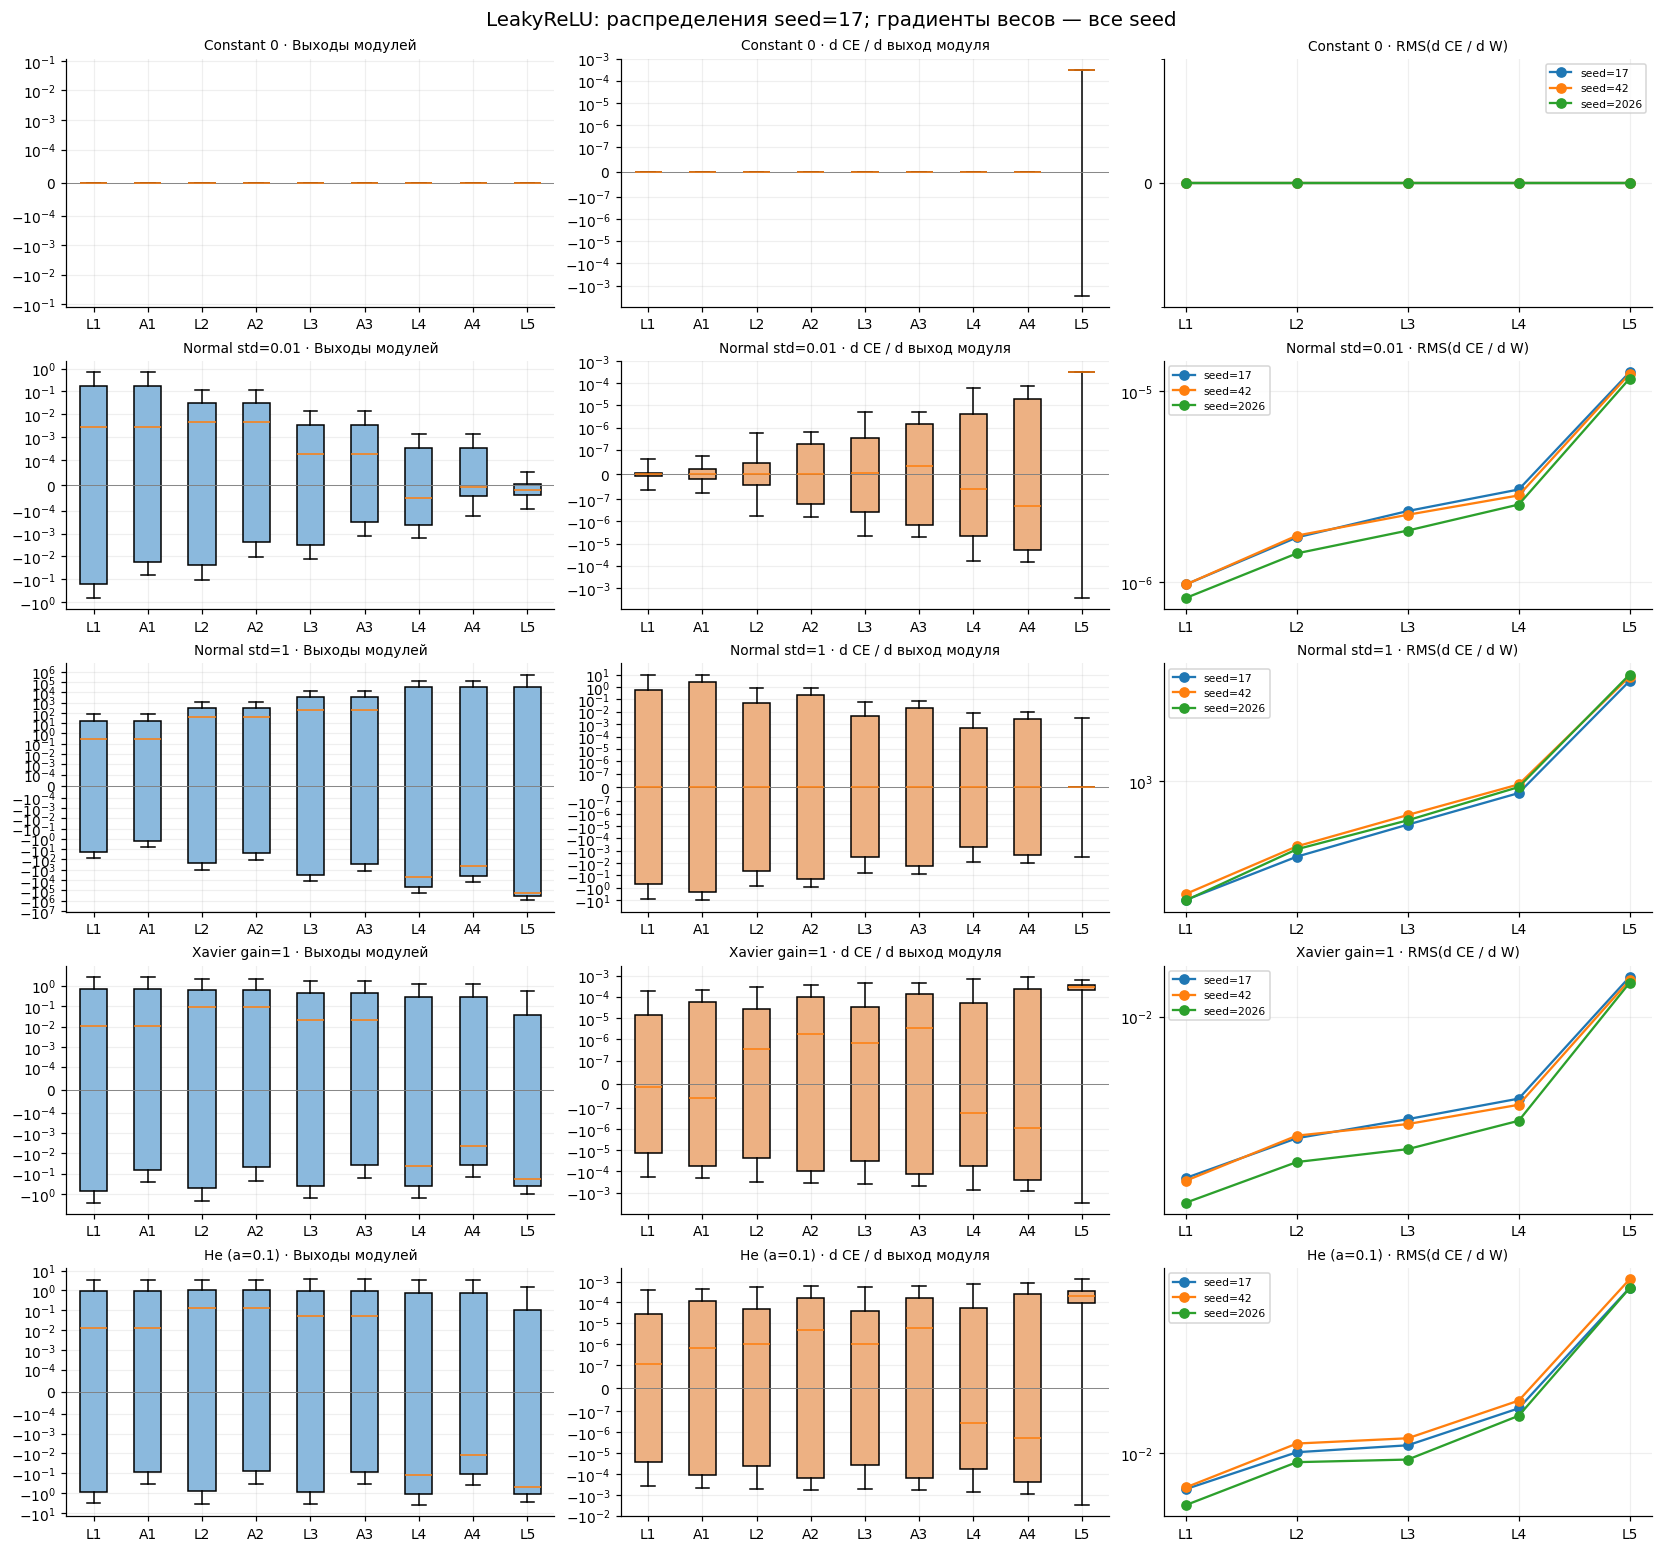

In [5]:
def plot_layer_distributions(activation):
    fig, axes = plt.subplots(len(INITIALIZATIONS), 3, figsize=(15, 14),
                             layout="constrained")
    for row, initialization in enumerate(INITIALIZATIONS):
        boxes = diagnostic_boxes[activation, initialization]
        label = INIT_LABELS[initialization]
        if initialization == "matched":
            label = MATCHED_LABELS[activation]
        for col, (stats, threshold, title) in enumerate([
            (boxes[0], 1e-4, "Выходы модулей"),
            (boxes[1], 1e-7, "d CE / d выход модуля"),
        ]):
            ax = axes[row, col]
            artists = ax.bxp(stats, showfliers=False, patch_artist=True)
            for patch in artists["boxes"]:
                patch.set_facecolor("#8bb9dd" if col == 0 else "#edb183")
            ax.set_yscale("symlog", linthresh=threshold)
            ax.axhline(0, color="gray", lw=0.6)
            ax.set_title(f"{label} · {title}", fontsize=9)
        weights = weight_stats.query("activation == @activation and init == @initialization")
        for seed in SEEDS:
            w = weights[weights.seed == seed]
            axes[row, 2].plot(w.layer, w.weight_grad_rms, marker="o", label=f"seed={seed}")
        axes[row, 2].set_yscale("symlog", linthresh=1e-9)
        if weights.weight_grad_rms.eq(0).all():
            axes[row, 2].set_ylim(-1e-9, 1e-9)
            axes[row, 2].set_yticks([0])
        axes[row, 2].set_title(f"{label} · RMS(d CE / d W)", fontsize=9)
        axes[row, 2].legend(fontsize=7)
    fig.suptitle(f"{activation}: распределения seed={SEEDS[0]}; градиенты весов — все seed", fontsize=13)
    plt.show()

for activation in ACTIVATIONS:
    plot_layer_distributions(activation)


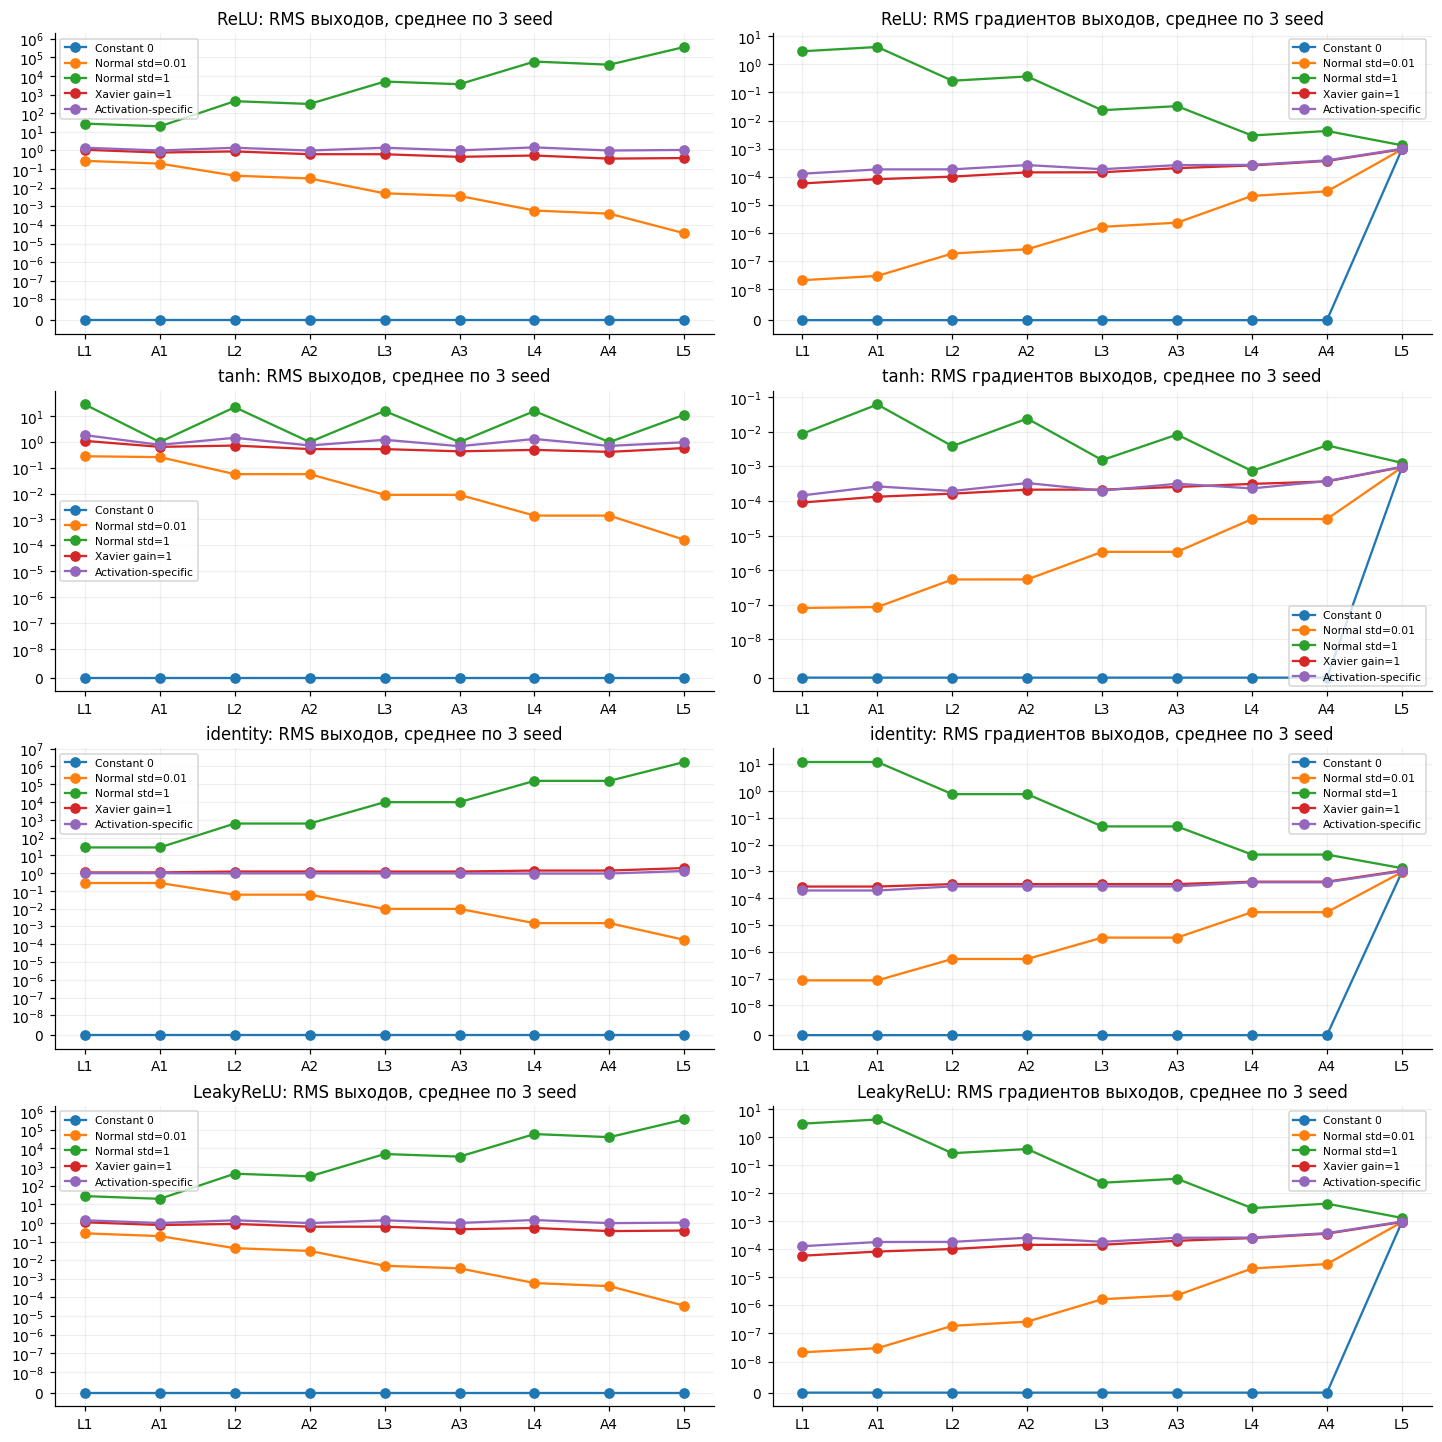

,activation,init,RMS A1,RMS A4,RMS grad A1,RMS grad A4,zeros A4,saturation A4
0,LeakyReLU,matched,0.994,0.981,0.000184,0.000381,0,—
1,LeakyReLU,normal_large,19.8,4.06e+04,4.31,0.00428,0,—
2,LeakyReLU,normal_small,0.198,0.000406,2.99e-08,3e-05,0,—
3,LeakyReLU,xavier,0.777,0.367,8.37e-05,0.000365,0,—
4,LeakyReLU,zeros,0,0,0,0,1,—
5,ReLU,matched,0.994,0.994,0.000182,0.000381,0.502,—
6,ReLU,normal_large,19.7,4.03e+04,4.18,0.00426,0.502,—
7,ReLU,normal_small,0.197,0.000403,2.92e-08,3e-05,0.502,—
8,ReLU,xavier,0.773,0.364,8.16e-05,0.000364,0.502,—
9,ReLU,zeros,0,0,0,0,1,—


### Какие инициализации сохраняют масштаб

Измерения до обучения, среднее по трём seed:

* **ReLU**: He (ReLU) даёт RMS A1 → A4 0.994 → 0.994; Xavier gain=1: 0.773 → 0.364. Для He (ReLU) RMS градиента A1/A4 = 0.48: градиент первого скрытого выхода остаётся того же порядка.
* **tanh**: Xavier gain=5/3 даёт RMS A1 → A4 0.766 → 0.698; Xavier gain=1: 0.640 → 0.410. Для Xavier gain=5/3 RMS градиента A1/A4 = 0.70: градиент первого скрытого выхода остаётся того же порядка.
* **identity**: LeCun normal даёт RMS A1 → A4 0.991 → 0.947; Xavier gain=1: 1.090 → 1.388. Для LeCun normal RMS градиента A1/A4 = 0.49: градиент первого скрытого выхода остаётся того же порядка.
* **LeakyReLU**: He (a=0.1) даёт RMS A1 → A4 0.994 → 0.981; Xavier gain=1: 0.777 → 0.367. Для He (a=0.1) RMS градиента A1/A4 = 0.48: градиент первого скрытого выхода остаётся того же порядка.

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13), layout="constrained")
for row, activation in enumerate(ACTIVATIONS):
    for initialization in INITIALIZATIONS:
        group = layer_stats.query("activation == @activation and init == @initialization")
        average = group.groupby("position")[["activation_rms", "gradient_rms"]].mean()
        names = group[group.seed == SEEDS[0]].sort_values("position").layer.tolist()
        for col, metric in enumerate(["activation_rms", "gradient_rms"]):
            axes[row, col].plot(names, average[metric], marker="o",
                                label=INIT_LABELS[initialization])
    for col, title in enumerate(["RMS выходов", "RMS градиентов выходов"]):
        axes[row, col].set_title(f"{activation}: {title}, среднее по 3 seed")
        axes[row, col].set_yscale("symlog", linthresh=1e-8)
        axes[row, col].legend(fontsize=7)
plt.show()

# Числа для обсуждения масштаба между первым и последним скрытыми слоями.
hidden_summary = []
for (activation, initialization), group in layer_stats.groupby(["activation", "init"]):
    first, last = group[group.layer == "A1"], group[group.layer == "A4"]
    hidden_summary.append({"activation": activation, "init": initialization,
                           "RMS A1": first.activation_rms.mean(),
                           "RMS A4": last.activation_rms.mean(),
                           "RMS grad A1": first.gradient_rms.mean(),
                           "RMS grad A4": last.gradient_rms.mean(),
                           "zeros A4": last.zero_fraction.mean(),
                           "saturation A4": last.tanh_saturation.mean()})
hidden_summary = pd.DataFrame(hidden_summary)
readable_hidden_summary = hidden_summary.copy()
for column in readable_hidden_summary.columns[2:]:
    readable_hidden_summary[column] = readable_hidden_summary[column].map(
        lambda value: "—" if pd.isna(value) else f"{value:.3g}")
display(readable_hidden_summary)

stability_lines = ["### Какие инициализации сохраняют масштаб", "",
                   "Измерения до обучения, среднее по трём seed:", ""]
for activation in ACTIVATIONS:
    matched = hidden_summary.query("activation == @activation and init == 'matched'").iloc[0]
    xavier = hidden_summary.query("activation == @activation and init == 'xavier'").iloc[0]
    stability_lines.append(
        f"* **{activation}**: {MATCHED_LABELS[activation]} даёт RMS A1 → A4 "
        f"{matched['RMS A1']:.3f} → {matched['RMS A4']:.3f}; "
        f"Xavier gain=1: {xavier['RMS A1']:.3f} → {xavier['RMS A4']:.3f}. "
        f"Для {MATCHED_LABELS[activation]} RMS градиента A1/A4 = "
        f"{matched['RMS grad A1'] / matched['RMS grad A4']:.2f}: "
        "градиент первого скрытого выхода остаётся того же порядка.")
display(Markdown("\n".join(stability_lines)))


## 4. Сходимость на FashionMNIST

Каждая из 20 комбинаций обучается с тремя seed, по 10 эпох, `SGD(lr=0.03)` без momentum,
weight decay, scheduler и clipping. Сравниваем изменение **только активации и инициализации**.
Общий learning rate делает сравнение контролируемым, но не доказывает превосходство
при индивидуальной настройке каждого варианта.

На эпохе 0 и после каждой эпохи считаем train/validation CE и accuracy на всей соответствующей
выборке в `eval()` без градиентов. Это метрики одной фиксированной модели, а не усреднение
потерь меняющейся модели внутри эпохи. Отдельно записываем среднюю норму градиента параметров
по обучающим батчам. Метрики взвешены по числу объектов, включая последний неполный батч.

При нечисловых потерях/градиентах или CE > 10⁶ останавливаем конкретный запуск и явно
помечаем причину. Последний порог — защита от бессмысленного вычисления при взрыве,
а не доказательство математической расходимости. После остановки кривые обрываются;
пропущенные эпохи не заполняются выдуманными значениями.


In [7]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, total_correct, total_size = 0.0, 0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        logits = model(inputs)
        loss = nn.functional.cross_entropy(logits, targets, reduction="sum")
        total_loss += loss.item()
        total_correct += (logits.argmax(1) == targets).sum().item()
        total_size += len(targets)
    return total_loss / total_size, total_correct / total_size

def run_experiment(activation, initialization, seed):
    model = make_model(activation, initialization, seed)
    shuffle_generator = torch.Generator().manual_seed(seed + 10000)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              generator=shuffle_generator, num_workers=0)
    train_eval_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False,
                                   num_workers=0)
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)
    history, best_state = [], None
    best_val_loss, best_epoch = float("inf"), None
    status, elapsed_start = "completed", time.perf_counter()
    failure_epoch, failure_value = None, float("nan")

    def record(epoch, grad_norm):
        nonlocal best_state, best_val_loss, best_epoch
        train_loss, train_accuracy = evaluate(model, train_eval_loader)
        val_loss, val_accuracy = evaluate(model, val_loader)
        history.append({"activation": activation, "init": initialization, "seed": seed,
                        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "train_accuracy": train_accuracy, "val_accuracy": val_accuracy,
                        "grad_norm": grad_norm})
        if math.isfinite(val_loss) and val_loss < best_val_loss:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = {name: value.detach().cpu().clone()
                          for name, value in model.state_dict().items()}
        return train_loss, val_loss

    train_loss, val_loss = record(0, float("nan"))
    if not (math.isfinite(train_loss) and math.isfinite(val_loss)) or train_loss > 1e6:
        status, failure_epoch, failure_value = "initial_loss_overflow", 0, train_loss
    else:
        for epoch in range(1, EPOCHS + 1):
            model.train()
            norm_sum, batches = 0.0, 0
            for inputs, targets in train_loader:
                inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = nn.functional.cross_entropy(model(inputs), targets)
                loss_value = loss.item()
                if not math.isfinite(loss_value) or loss_value > 1e6:
                    status, failure_value = "batch_loss_overflow", loss_value
                    break
                loss.backward()
                grad_norm = torch.stack([p.grad.detach().norm() for p in model.parameters()]).norm()
                if not torch.isfinite(grad_norm):
                    status, failure_value = "nonfinite_gradient", grad_norm.item()
                    break
                norm_sum += grad_norm.item()
                batches += 1
                optimizer.step()
            if status != "completed":
                failure_epoch = epoch
                break
            train_loss, val_loss = record(epoch, norm_sum / batches)
            if not (math.isfinite(train_loss) and math.isfinite(val_loss)) or train_loss > 1e6:
                status, failure_epoch, failure_value = "epoch_loss_overflow", epoch, train_loss
                break
    summary = {"activation": activation, "init": initialization, "seed": seed,
               "status": status, "epochs_done": history[-1]["epoch"],
               "best_epoch": best_epoch, "best_val_loss": best_val_loss,
               "final_train_loss": history[-1]["train_loss"],
               "final_val_loss": history[-1]["val_loss"],
               "final_val_accuracy": history[-1]["val_accuracy"],
               "failure_epoch": failure_epoch, "failure_value": failure_value,
               "seconds": time.perf_counter() - elapsed_start}
    return history, summary, best_state


In [8]:
all_history, all_runs, best_states = [], [], {}
experiment_start = time.perf_counter()
for activation in ACTIVATIONS:
    for initialization in INITIALIZATIONS:
        for seed in SEEDS:
            history, summary, state = run_experiment(activation, initialization, seed)
            all_history.extend(history)
            all_runs.append(summary)
            if summary["status"] == "completed":
                best_states[activation, initialization, seed] = state
            print(f"{activation:10s} | {initialization:12s} | seed={seed:4d} | "
                  f"{summary['status']:24s} | val acc={summary['final_val_accuracy']:.4f}",
                  flush=True)
history_df, runs_df = pd.DataFrame(all_history), pd.DataFrame(all_runs)
print(f"Всего: {len(runs_df)} запусков, {(time.perf_counter() - experiment_start) / 60:.1f} мин.")


ReLU       | zeros        | seed=  17 | completed                | val acc=0.1000
ReLU       | zeros        | seed=  42 | completed                | val acc=0.1000
ReLU       | zeros        | seed=2026 | completed                | val acc=0.1000
ReLU       | normal_small | seed=  17 | completed                | val acc=0.1000
ReLU       | normal_small | seed=  42 | completed                | val acc=0.1000
ReLU       | normal_small | seed=2026 | completed                | val acc=0.2311
ReLU       | normal_large | seed=  17 | batch_loss_overflow      | val acc=0.1373
ReLU       | normal_large | seed=  42 | batch_loss_overflow      | val acc=0.0539
ReLU       | normal_large | seed=2026 | batch_loss_overflow      | val acc=0.1206
ReLU       | xavier       | seed=  17 | completed                | val acc=0.8732
ReLU       | xavier       | seed=  42 | completed                | val acc=0.8801
ReLU       | xavier       | seed=2026 | completed                | val acc=0.8792
ReLU       | mat

In [9]:
# Статус виден для каждой конфигурации; средние не скрывают неудачные запуски.
completion = runs_df.groupby(["activation", "init"]).agg(
    completed=("status", lambda x: int((x == "completed").sum())),
    total=("status", "size"))
completed_runs = runs_df[runs_df.status == "completed"]
metrics = completed_runs.groupby(["activation", "init"]).agg(
    train_ce=("final_train_loss", "mean"),
    val_ce=("final_val_loss", "mean"),
    val_ce_std=("final_val_loss", "std"),
    val_acc=("final_val_accuracy", "mean"),
    val_acc_std=("final_val_accuracy", "std"),
    best_val_ce=("best_val_loss", "mean"),
    best_epoch=("best_epoch", "mean"))
comparison = completion.join(metrics)
display(comparison.round(4))
failures = runs_df[runs_df.status != "completed"]
if not failures.empty:
    display(failures[["activation", "init", "seed", "status", "failure_epoch",
                      "failure_value"]])


completed  total  train_ce  val_ce  val_ce_std  \
activation init                                                           
LeakyReLU  matched               3      3    0.2700  0.3281      0.0164   
           normal_large          0      3       NaN     NaN         NaN   
           normal_small          3      3    2.3021  2.3021      0.0001   
           xavier                3      3    0.2951  0.3305      0.0067   
           zeros                 3      3    2.3026  2.3026      0.0000   
ReLU       matched               3      3    0.2605  0.3248      0.0088   
           normal_large          0      3       NaN     NaN         NaN   
           normal_small          3      3    2.3022  2.3022      0.0001   
           xavier                3      3    0.2910  0.3288      0.0032   
           zeros                 3      3    2.3026  2.3026      0.0000   
identity   matched               3      3    0.4216  0.4337      0.0013   
           normal_large          0      3       NaN     NaN         NaN   
           normal_small          3      3    0.8506  0.8320      0.0101   
           xavier                3      3    0.4219  0.4360      0.0014   
           zeros                 3      3    2.3026  2.3026      0.0000   
tanh       matched               3      3    0.2482  0.3279      0.0050   
           normal_large          3      3    2.1038  2.0708      0.0496   
           normal_small          3      3    0.8980  0.8854      0.0508   
           xavier                3      3    0.2958  0.3269      0.0057   
           zeros                 3      3    2.3026  2.3026      0.0000   

                         val_acc  val_acc_std  best_val_ce  best_epoch  
activation init                                                         
LeakyReLU  matched        0.8760       0.0066       0.3281      9.6667  
           normal_large      NaN          NaN          NaN         NaN  
           normal_small   0.1481       0.0833       2.3021     10.0000  
           xavier         0.8767       0.0029       0.3305     10.0000  
           zeros          0.1000       0.0000       2.3026      0.0000  
ReLU       matched        0.8781       0.0055       0.3235      9.6667  
           normal_large      NaN          NaN          NaN         NaN  
           normal_small   0.1437       0.0757       2.3022     10.0000  
           xavier         0.8775       0.0038       0.3282      9.6667  
           zeros          0.1000       0.0000       2.3026      0.0000  
identity   matched        0.8465       0.0012       0.4304      6.3333  
           normal_large      NaN          NaN          NaN         NaN  
           normal_small   0.6881       0.0104       0.8320     10.0000  
           xavier         0.8460       0.0011       0.4315      6.3333  
           zeros          0.1000       0.0000       2.3026      0.0000  
tanh       matched        0.8803       0.0007       0.3279     10.0000  
           normal_large   0.6042       0.0103       2.0708     10.0000  
           normal_small   0.6650       0.0210       0.8854     10.0000  
           xavier         0.8809       0.0023       0.3269     10.0000  
           zeros          0.1000       0.0000       2.3026      0.0000

,activation,init,seed,status,failure_epoch,failure_value
6,ReLU,normal_large,17,batch_loss_overflow,1.0,6.558893e+15
7,ReLU,normal_large,42,batch_loss_overflow,1.0,1.844775e+16
8,ReLU,normal_large,2026,batch_loss_overflow,1.0,2.339379e+16
36,identity,normal_large,17,initial_loss_overflow,0.0,2.665852e+06
37,identity,normal_large,42,initial_loss_overflow,0.0,2.659700e+06
38,identity,normal_large,2026,initial_loss_overflow,0.0,2.620420e+06
51,LeakyReLU,normal_large,17,batch_loss_overflow,1.0,8.002435e+15
52,LeakyReLU,normal_large,42,batch_loss_overflow,1.0,5.058258e+15
53,LeakyReLU,normal_large,2026,batch_loss_overflow,1.0,1.277139e+16


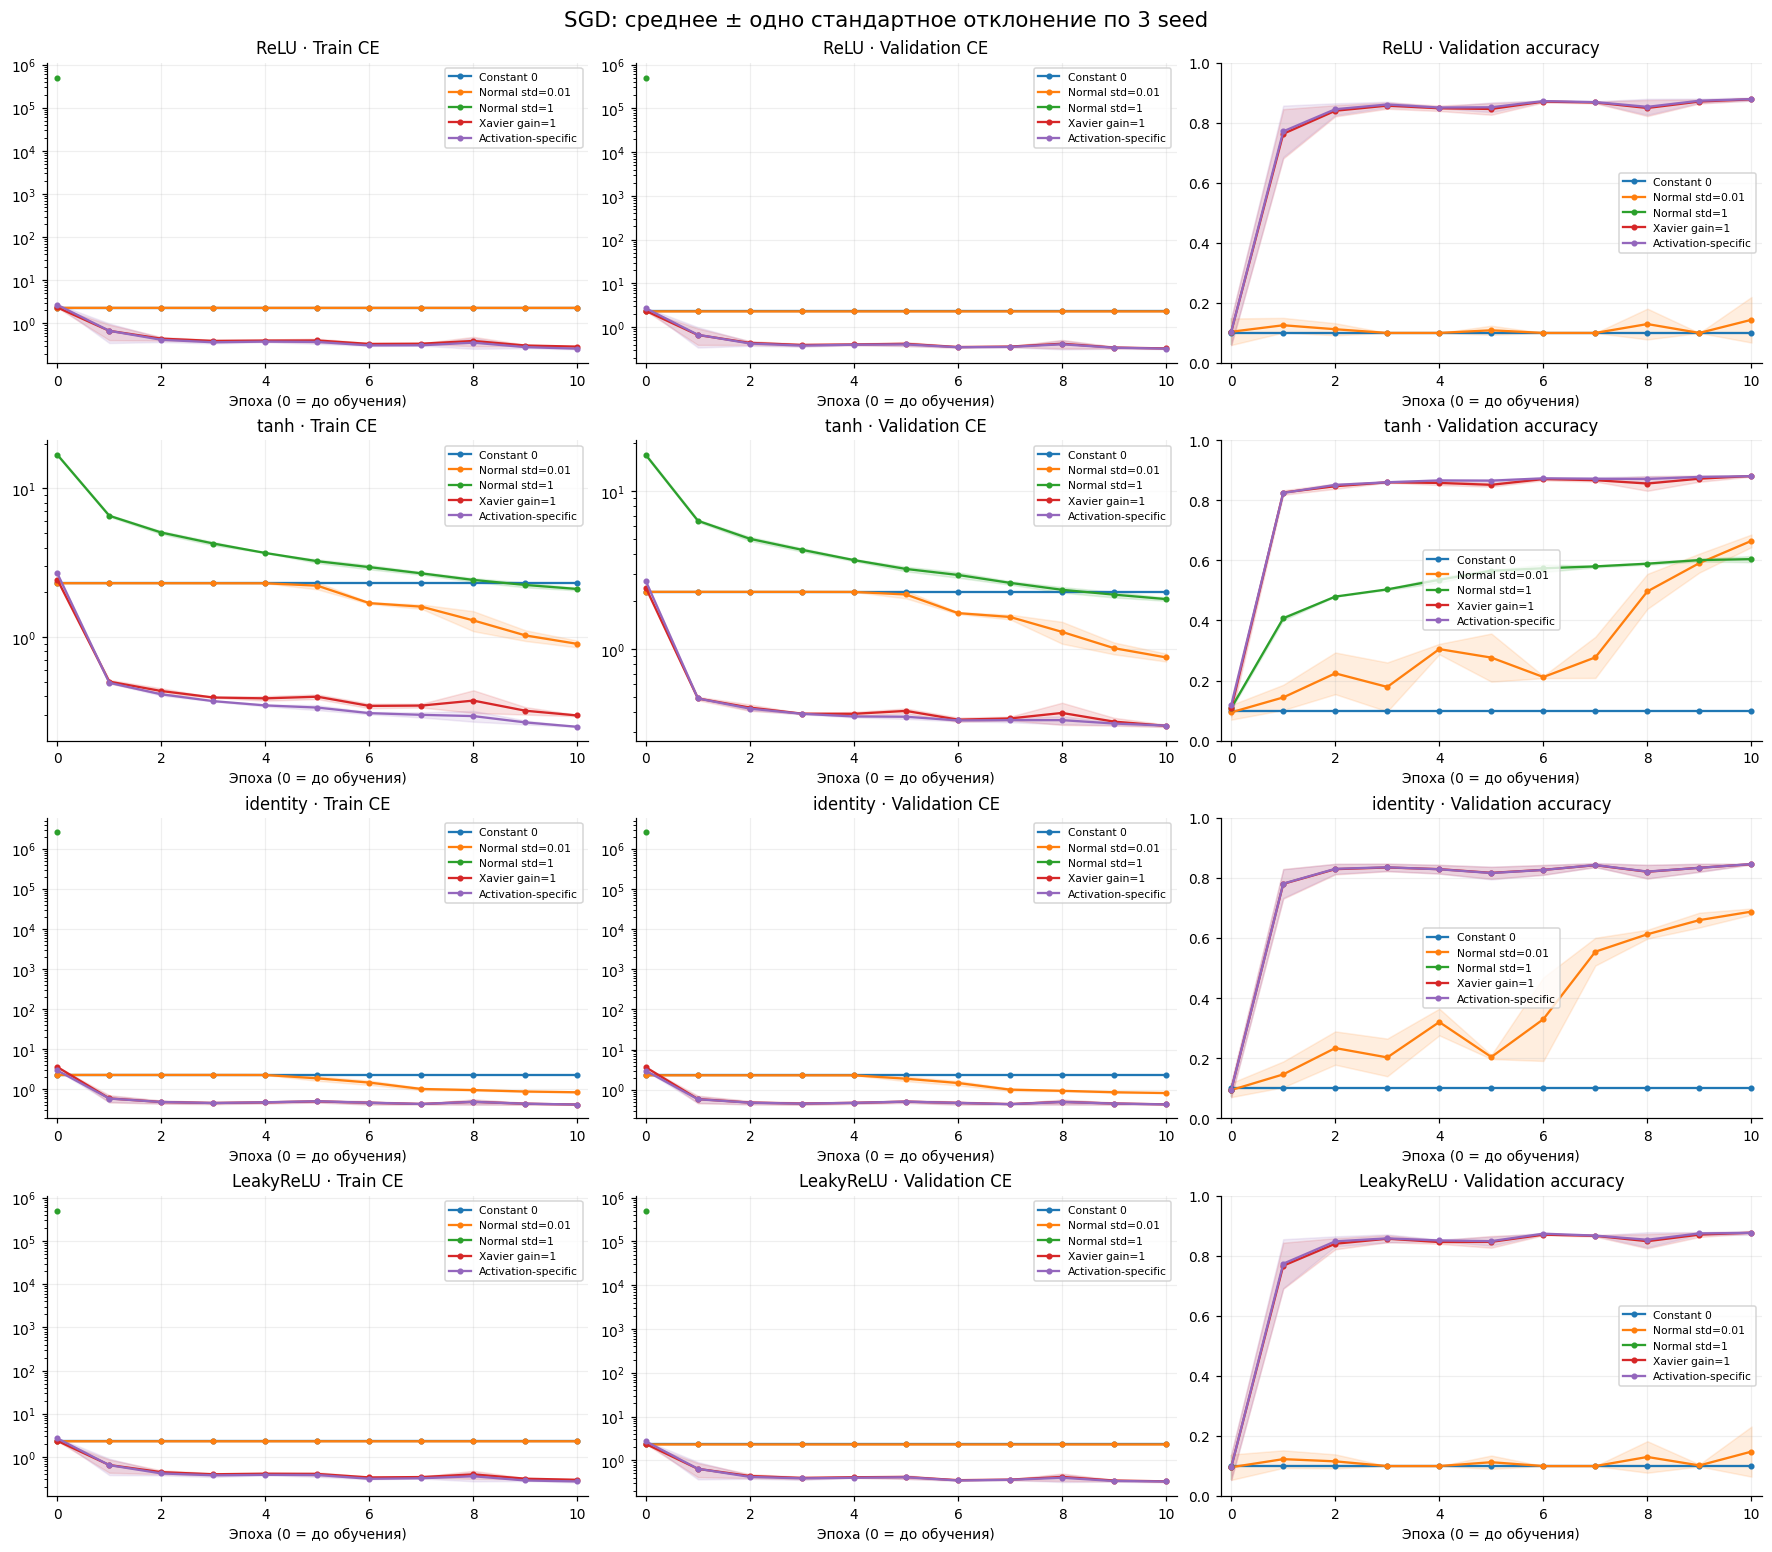

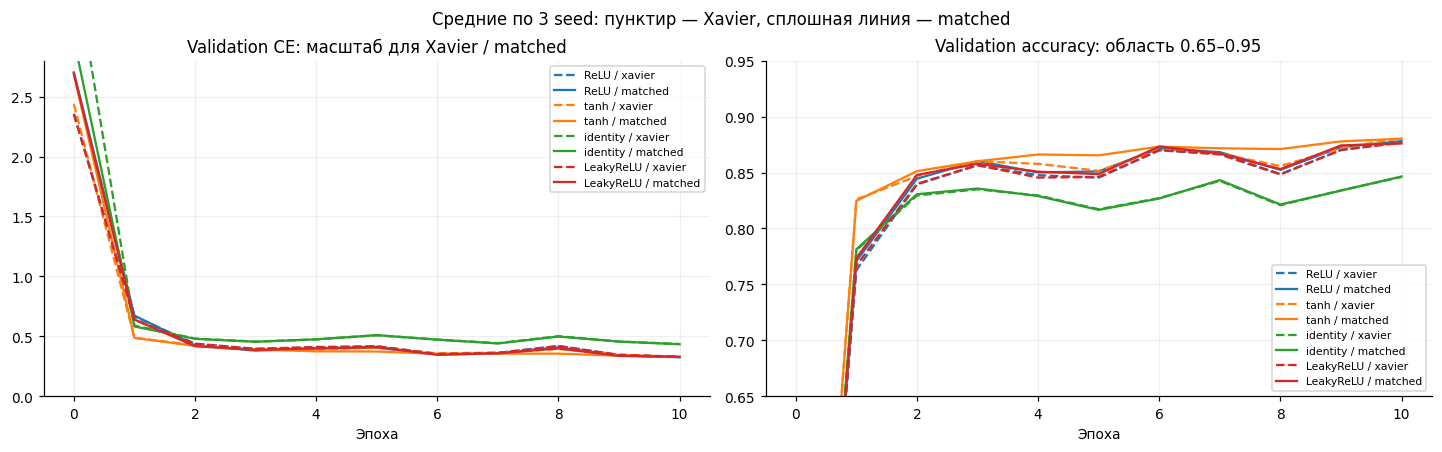

In [10]:
colors = dict(zip(INITIALIZATIONS, plt.get_cmap("tab10").colors[:5]))
fig, axes = plt.subplots(4, 3, figsize=(16, 14), layout="constrained")
for row, activation in enumerate(ACTIVATIONS):
    for initialization in INITIALIZATIONS:
        group = history_df.query("activation == @activation and init == @initialization")
        for col, metric in enumerate(["train_loss", "val_loss", "val_accuracy"]):
            aggregate = group.groupby("epoch")[metric].agg(["mean", "std", "count"])
            # Не усредняем только выжившие seed после остановки остальных.
            aggregate = aggregate[aggregate["count"] == len(SEEDS)]
            mean, std = aggregate["mean"], aggregate["std"].fillna(0)
            ax = axes[row, col]
            ax.plot(mean.index, mean, marker=".", color=colors[initialization],
                    label=INIT_LABELS[initialization])
            ax.fill_between(mean.index, mean - std, mean + std,
                            color=colors[initialization], alpha=0.13)
    for col, title in enumerate(["Train CE", "Validation CE", "Validation accuracy"]):
        ax = axes[row, col]
        ax.set_title(f"{activation} · {title}")
        ax.set_xlabel("Эпоха (0 = до обучения)")
        ax.set_xlim(-0.2, EPOCHS + 0.2)
        if col < 2:
            ax.set_yscale("log")
        else:
            ax.set_ylim(0, 1)
        ax.legend(fontsize=7)
fig.suptitle("SGD: среднее ± одно стандартное отклонение по 3 seed", fontsize=14)
plt.show()

# Увеличенный масштаб для устойчивых вариантов; общие графики выше содержат все контроли.
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
activation_colors = dict(zip(ACTIVATIONS, plt.get_cmap("tab10").colors[:4]))
for activation in ACTIVATIONS:
    for initialization, linestyle in [("xavier", "--"), ("matched", "-")]:
        group = history_df.query("activation == @activation and init == @initialization")
        for ax, metric in zip(axes, ["val_loss", "val_accuracy"]):
            average = group.groupby("epoch")[metric].mean()
            ax.plot(average.index, average, linestyle=linestyle,
                    color=activation_colors[activation], label=f"{activation} / {initialization}")
fig.suptitle("Средние по 3 seed: пунктир — Xavier, сплошная линия — matched")
axes[0].set_ylim(0, 2.8)
axes[0].set_title("Validation CE: масштаб для Xavier / matched")
axes[1].set_ylim(0.65, 0.95)
axes[1].set_title("Validation accuracy: область 0.65–0.95")
for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.legend(fontsize=7)
plt.show()


Полосы на графиках — разброс по трём seed, не доверительные интервалы и не оценка
вариативности разбиения. Epoch 0 отделяет хороший старт от скорости обучения.
Из-за общего learning rate результаты относятся к указанному протоколу;
10 эпох достаточно для сравнения ранней сходимости, но не для доказательства достижения
глобального минимума или окончательной точности каждой модели.


In [11]:
# Для каждой активации выбираем инициализацию по средней лучшей validation CE.
# К тесту допускаются только варианты, завершившие все три запуска.
eligible = comparison[comparison.completed == len(SEEDS)].reset_index()
selected = eligible.loc[eligible.groupby("activation").best_val_ce.idxmin(),
                         ["activation", "init", "best_val_ce"]].reset_index(drop=True)
display(selected.round(4))

raw_test = FashionMNIST(root=DATA_ROOT, train=False, download=True)
test_x = raw_test.data.float().unsqueeze(1).div_(255).sub_(train_mean).div_(train_std)
test_loader = DataLoader(TensorDataset(test_x, raw_test.targets), batch_size=1024,
                         shuffle=False, num_workers=0)
test_rows = []
for row in selected.itertuples(index=False):
    for seed in SEEDS:
        model = make_model(row.activation, row.init, seed)
        model.load_state_dict(best_states[row.activation, row.init, seed])
        test_ce, test_accuracy = evaluate(model, test_loader)
        test_rows.append({"activation": row.activation, "init": row.init, "seed": seed,
                          "test_ce": test_ce, "test_accuracy": test_accuracy})
test_df = pd.DataFrame(test_rows)
test_summary = test_df.groupby(["activation", "init"]).agg(
    test_ce=("test_ce", "mean"), test_ce_std=("test_ce", "std"),
    test_accuracy=("test_accuracy", "mean"), test_accuracy_std=("test_accuracy", "std"))
display(test_summary.round(4))


,activation,init,best_val_ce
0,LeakyReLU,matched,0.3281
1,ReLU,matched,0.3235
2,identity,matched,0.4304
3,tanh,xavier,0.3269


,,test_ce,test_ce_std,test_accuracy,test_accuracy_std
activation,init,,,,
LeakyReLU,matched,0.3730,0.0133,0.8670,0.0046
ReLU,matched,0.3701,0.0086,0.8690,0.0015
identity,matched,0.4767,0.0016,0.8312,0.0010
tanh,xavier,0.3719,0.0046,0.8646,0.0025


## 5. Проверки корректности и выводы

Проверим, что сравнение использовало заданную архитектуру, все комбинации и seed,
что нулевые веса действительно блокируют обучение скрытых слоёв и что модель с identity
эквивалентна одному аффинному преобразованию. Эти проверки не требуют предполагать
какую-либо заранее желаемую точность.


In [12]:
assert len(runs_df) == len(ACTIVATIONS) * len(INITIALIZATIONS) * len(SEEDS)
assert not runs_df.duplicated(["activation", "init", "seed"]).any()
assert layer_stats.groupby(["activation", "init", "seed"]).size().eq(9).all()
assert weight_stats.groupby(["activation", "init", "seed"]).size().eq(5).all()
assert completed_runs.epochs_done.eq(EPOCHS).all()
assert sum(p.numel() for p in example_model.parameters()) == 633226
for activation in ACTIVATIONS:
    model = make_model(activation, "zeros", SEEDS[0])
    loss = nn.functional.cross_entropy(model(probe_x), probe_y)
    loss.backward()
    for layer in model.layers:
        if isinstance(layer, nn.Linear):
            assert torch.count_nonzero(layer.weight.grad) == 0

# Свести композицию identity-слоёв в одну матрицу и смещение.
identity_model = make_model("identity", "xavier", SEEDS[0]).double()
with torch.no_grad():
    # Ненулевые смещения проверяют и аффинную часть, не только произведение матриц.
    for layer in identity_model.layers:
        if isinstance(layer, nn.Linear):
            layer.bias.uniform_(-0.1, 0.1)
    effective_weight = torch.eye(784, dtype=torch.float64)
    effective_bias = torch.zeros(784, dtype=torch.float64)
    for layer in identity_model.layers:
        if isinstance(layer, nn.Linear):
            effective_weight = layer.weight @ effective_weight
            effective_bias = layer.weight @ effective_bias + layer.bias
    x_check = probe_x[:8].double()
    collapsed = x_check.flatten(1) @ effective_weight.T + effective_bias
    torch.testing.assert_close(identity_model(x_check), collapsed, rtol=1e-10, atol=1e-10)
print("Проверки пройдены: 60 экспериментов, 9 выходов и 5 градиентов весов; нули; identity.")


Проверки пройдены: 60 экспериментов, 9 выходов и 5 градиентов весов; нули; identity.


In [13]:
# Краткий численный отчёт генерируется из фактически рассчитанных таблиц.
lines = ["### Результаты выполненного эксперимента", "",
         "Варианты выбраны по validation CE; test не участвовал в выборе.", ""]
for row in selected.itertuples(index=False):
    s = test_summary.loc[(row.activation, row.init)]
    h = hidden_summary.query("activation == @row.activation and init == @row.init").iloc[0]
    lines.append(
        f"* **{row.activation}, {row.init}**: test accuracy "
        f"{100 * s.test_accuracy:.2f} ± {100 * s.test_accuracy_std:.2f}% (SD по seed); "
        f"test CE {s.test_ce:.4f}. Начальные RMS A1 → A4: "
        f"{h['RMS A1']:.3g} → {h['RMS A4']:.3g}; "
        f"RMS градиента A1 → A4: {h['RMS grad A1']:.3g} → {h['RMS grad A4']:.3g}.")
lines += ["", f"Завершено {len(completed_runs)}/{len(runs_df)} запусков. "
          f"Защитная остановка: {len(failures)}; причины приведены выше."]
display(Markdown("\n".join(lines)))


### Результаты выполненного эксперимента

Варианты выбраны по validation CE; test не участвовал в выборе.

* **LeakyReLU, matched**: test accuracy 86.70 ± 0.46% (SD по seed); test CE 0.3730. Начальные RMS A1 → A4: 0.994 → 0.981; RMS градиента A1 → A4: 0.000184 → 0.000381.
* **ReLU, matched**: test accuracy 86.90 ± 0.15% (SD по seed); test CE 0.3701. Начальные RMS A1 → A4: 0.994 → 0.994; RMS градиента A1 → A4: 0.000182 → 0.000381.
* **identity, matched**: test accuracy 83.12 ± 0.10% (SD по seed); test CE 0.4767. Начальные RMS A1 → A4: 0.991 → 0.947; RMS градиента A1 → A4: 0.000193 → 0.000391.
* **tanh, xavier**: test accuracy 86.46 ± 0.25% (SD по seed); test CE 0.3719. Начальные RMS A1 → A4: 0.64 → 0.41; RMS градиента A1 → A4: 0.000133 → 0.000367.

Завершено 51/60 запусков. Защитная остановка: 9; причины приведены выше.

### Интерпретация

1. **Константа 0 не подходит ни одной из рассмотренных активаций.** Нулевые матрицы
   блокируют передачу градиента к ранним слоям; для ReLU дополнительно $f'(0)=0$.
   Модель учит только частоты классов через последнее смещение и остаётся около 10% accuracy.
   Даже если константные выходы не «взрываются», это не полезная стабильность.
2. **Normal std=0.01 слишком мала для этой глубины.** Выходы и градиенты весов сильно
   затухают. Знаковое среднее градиента может быть близко к нулю даже при больших отдельных координатах;
   поэтому выше измерены RMS и распределения, а не только знаковое среднее.
   Затухание на старте не означает невозможности обучения: tanh с маленькими весами
   в выполненном эксперименте частично восстанавливается за десять эпох.
3. **Normal std=1 слишком велика.** У identity и (Leaky)ReLU растут выходы и градиенты;
   у tanh выходы ограничены, но попадают в насыщение. Малый градиент tanh в насыщенных
   координатах может сосуществовать с большим RMS полного градиента из-за больших матриц
   весов и ненасыщенных координат. Одного диапазона активаций для диагноза недостаточно.
4. **Для ReLU и LeakyReLU естественный выбор — He с правильным gain.** Он компенсирует
   изменение второго момента нелинейностью. Xavier gain=1 тоже может успешно обучаться
   в этой сравнительно неглубокой сети; выбирать между ними следует по измерениям,
   а не объявлять He безусловным победителем по accuracy.
5. **Для tanh разумны Xavier gain=1 и gain=5/3.** Первый слабее насыщает нейроны,
   второй может лучше поддерживать масштаб по глубине. Таблицы насыщения, RMS и validation
   показывают конкретный компромисс; bounded-выход сам по себе не доказывает стабильность.
6. **Для identity подходят Xavier gain=1 или LeCun normal.** Первый балансирует
   два направления, второй ориентирован на прямой проход. Даже при хорошем масштабе
   увеличение числа identity-слоёв не добавляет нелинейной выразительности.
7. **LeakyReLU — дополнительный анализ.** Наклон 0.1 сохраняет ненулевую производную
   на отрицательных входах. Он не устраняет проблему неудачного масштаба весов;
   нулевые и чрезмерно большие веса остаются плохими начальными условиями.

Практический вывод: выбирать масштаб с учётом активации и ширины слоёв, проверять оба
направления распространения сигнала и затем измерять сходимость на валидации.
Хорошая инициализация облегчает оптимизацию, но не заменяет подходящие learning rate,
архитектуру и нормализацию данных. Численные выводы выше ограничены этой архитектурой,
разбиением, тремя seed и десятью эпохами SGD.
